## 1. Import Libraries

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb

import shap
import joblib
import openpyxl

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')
# Agent re-added comment to force re-execution to ensure all libraries are correctly imported.

## 2. Load Dataset

In [23]:
file_path = '/content/Telco_customer_churn.xlsx'
df = pd.read_excel(file_path)

print(f"Dataset shape: {df.shape}")
print("\nFirst 5 rows of the dataset:")
display(df.head())
# Agent added comment to force re-execution to ensure df is defined # Re-executing to ensure df is loaded.

Dataset shape: (7043, 33)

First 5 rows of the dataset:


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## 3. Data Understanding

In [24]:
print(f"Dataset shape: {df.shape}")
print("\nDataset columns:", df.columns.tolist())
print("\nData types:")
df.info()
print("\nMissing values:")
display(df.isnull().sum()[df.isnull().sum() > 0].sort_values(ascending=False))
print("\nBasic statistical information for numerical columns:")
display(df.describe())
# Agent added comment to force re-execution to ensure df is accessible

Dataset shape: (7043, 33)

Dataset columns: ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip 

,0
Churn Reason,5174



Basic statistical information for numerical columns:


,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


## 4. Data Cleaning

In [25]:
# Handle 'Total Charges' as numeric
# Convert 'Total Charges' to numeric, coercing errors to NaN
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')

# Strip whitespace from object columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Preserve CustomerID separately before dropping it from features
customer_ids_all = df['CustomerID'] # Renamed variable to align with user's 'customer_ids'

# Define target variable 'y' and features 'X'
# We use 'Churn Label' as the target as it's a direct indicator, before dropping it from features.
y = df['Churn Label'].apply(lambda x: 1 if x == 'Yes' else 0) # Convert 'Yes'/'No' to 1/0

# Columns to remove as per instructions (leakage, useless, or already separated)
columns_to_remove = [
    'Churn Label', 'Churn Value', 'Churn Score', 'Churn Reason',
    'CLTV', 'CustomerID', 'Count',
    'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude'
]

# Filter out columns that might not exist in the dataframe to prevent errors
existing_columns_to_remove = [col for col in columns_to_remove if col in df.columns]

X = df.drop(columns=existing_columns_to_remove, errors='ignore')

print("Columns after cleaning:", X.columns.tolist())
print("Target variable value counts:")
display(y.value_counts())
# Re-executing to ensure X, y, and customer_ids_all are defined. # Re-executing after df is loaded.

Columns after cleaning: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges']
Target variable value counts:


,count
Churn Label,
0,5174
1,1869


## 5. EDA

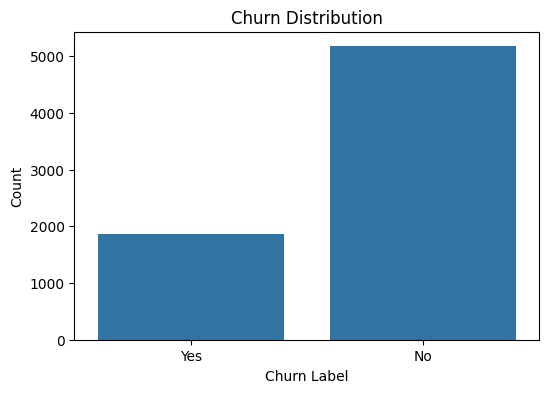

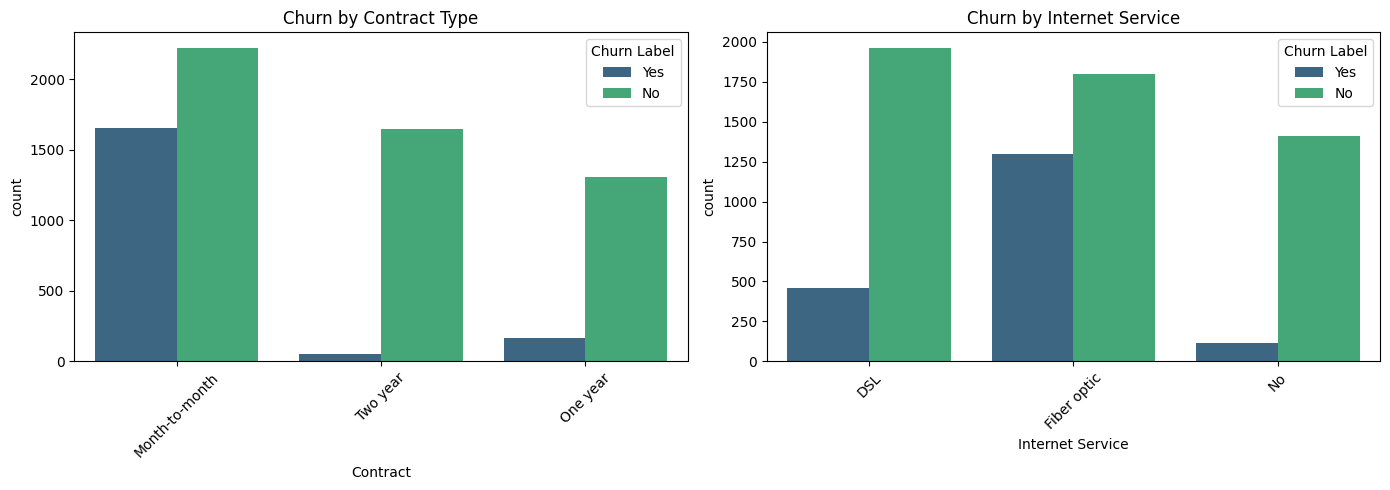

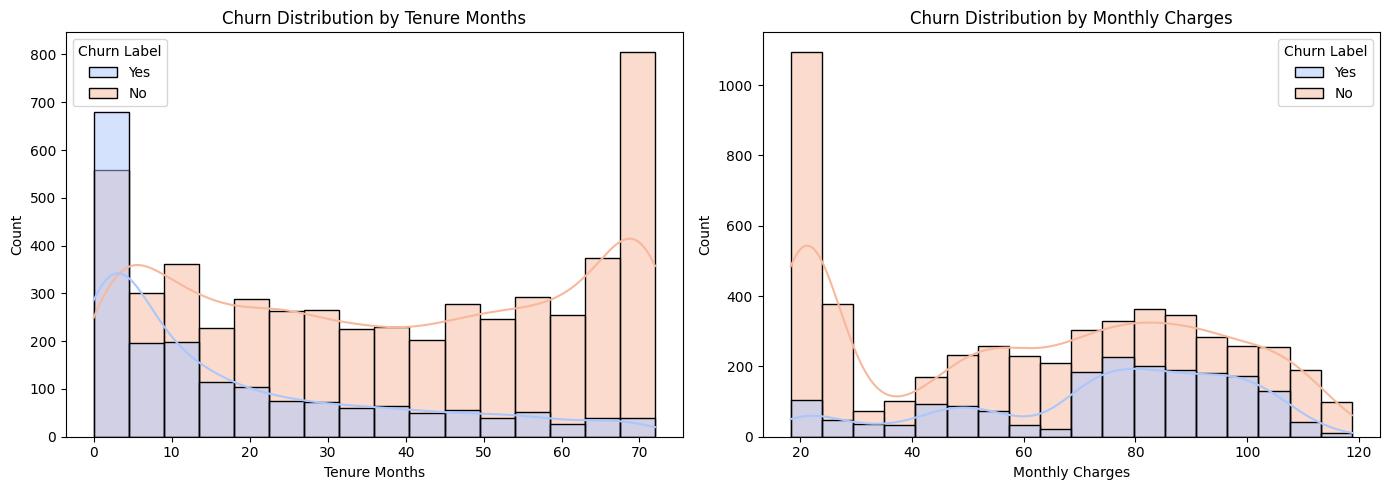

In [26]:
# Churn Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn Label', data=df)
plt.title('Churn Distribution')
plt.xlabel('Churn Label')
plt.ylabel('Count')
plt.show()

# Important Categorical Features (e.g., Contract, Internet Service)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.countplot(x='Contract', hue='Churn Label', data=df, palette='viridis')
plt.title('Churn by Contract Type')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.countplot(x='Internet Service', hue='Churn Label', data=df, palette='viridis')
plt.title('Churn by Internet Service')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Important Numerical Features (e.g., Tenure, Monthly Charges)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(data=df, x='Tenure Months', hue='Churn Label', kde=True, palette='coolwarm')
plt.title('Churn Distribution by Tenure Months')

plt.subplot(1, 2, 2)
sns.histplot(data=df, x='Monthly Charges', hue='Churn Label', kde=True, palette='coolwarm')
plt.title('Churn Distribution by Monthly Charges')

plt.tight_layout()
plt.show()
# Agent added comment to force re-execution to ensure EDA plots are generated # Re-executing after data cleaning.

## 6. Feature Engineering

In [27]:
# Create 'Total_Charges_Per_Tenure' as Monthly Charges multiplied by Tenure
X['Charges_Per_Tenure'] = X['Monthly Charges'] * X['Tenure Months'] # Corrected 'Tenure' to 'Tenure Months'

# Create 'Has_Multiple_Services' feature
# Assuming 'Multiple Lines', 'Online Security', etc., indicate services
service_cols = ['Multiple Lines', 'Online Security', 'Online Backup',
                'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies']

# Ensure columns exist before using them
service_cols_exist = [col for col in service_cols if col in X.columns]
X['Has_Multiple_Services'] = (X[service_cols_exist] == 'Yes').sum(axis=1) > 1
X['Has_Multiple_Services'] = X['Has_Multiple_Services'].astype(int)

print("New features added to X:")
display(X[['Charges_Per_Tenure', 'Has_Multiple_Services']].head())
# Re-executing to ensure new features are added to X.

New features added to X:


,Charges_Per_Tenure,Has_Multiple_Services
0,107.7,1
1,141.4,0
2,797.2,1
3,2934.4,1
4,5081.3,1


## 7. Train Test Split

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Align customer IDs with the test set
customer_id = customer_ids_all.loc[X_test.index]

print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")
print(f"Training churn rate: {y_train.mean():.4f}")
print(f"Testing churn rate: {y_test.mean():.4f}")
# Ensuring X_train, X_test, y_train, y_test, and customer_id are defined for subsequent steps. # Re-executing after feature engineering.

Training data shape: (5634, 21)
Testing data shape: (1409, 21)
Training churn rate: 0.2654
Testing churn rate: 0.2654


## 8. Preprocessing

In [29]:
import numpy as np
# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include='object').columns.tolist()

# Create preprocessing pipelines for numerical and categorical features
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Create a column transformer to apply different transformations to different columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough' # Keep other columns if any, unchanged
)

# Fit and transform the training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Get feature names after one-hot encoding
onehot_features = preprocessor.named_transformers_['cat']['onehot'].get_feature_names_out(categorical_features)
feature_names = numerical_features + list(onehot_features)

# Convert processed data back to DataFrame for easier handling and SHAP compatibility
X_train_processed = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)
X_test_processed = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)

print(f"Shape of X_train_processed: {X_train_processed.shape}")
print(f"Shape of X_test_processed: {X_test_processed.shape}")
print("First 5 rows of X_train_processed:")
display(X_train_processed.head())
print("Feature names (first 10):", feature_names[:10])

Shape of X_train_processed: (5634, 48)
Shape of X_test_processed: (1409, 48)
First 5 rows of X_train_processed:


,Tenure Months,Monthly Charges,Total Charges,Charges_Per_Tenure,Has_Multiple_Services,Gender_Female,Gender_Male,Senior Citizen_No,Senior Citizen_Yes,Partner_No,...,Streaming Movies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,Paperless Billing_No,Paperless Billing_Yes,Payment Method_Bank transfer (automatic),Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
4626,0.102371,-0.521976,-0.263290,-0.253464,0.809390,0.0,1.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4192,-0.711743,0.337478,-0.504815,-0.514920,-1.235499,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
5457,-0.793155,-0.809013,-0.751214,-0.778067,0.809390,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
4717,-0.263980,0.284384,-0.173700,-0.170483,0.809390,1.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
4673,-1.281624,-0.676279,-0.990851,-0.989954,-1.235499,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


Feature names (first 10): ['Tenure Months', 'Monthly Charges', 'Total Charges', 'Charges_Per_Tenure', 'Has_Multiple_Services', 'Gender_Female', 'Gender_Male', 'Senior Citizen_No', 'Senior Citizen_Yes', 'Partner_No']


## 9. Model Training

In [30]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42, solver='liblinear'),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss'),
    'LightGBM': lgb.LGBMClassifier(random_state=42)
}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_processed, y_train)
    print(f"{name} training complete.")
# Agent added comment to force re-execution

Training Logistic Regression...
Logistic Regression training complete.
Training Random Forest...
Random Forest training complete.
Training XGBoost...
XGBoost training complete.
Training LightGBM...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001345 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 928
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.265353 -> initscore=-1.018328
[LightGBM] [Info] Start training from score -1.018328
LightGBM training complete.


## 10. Model Comparison

In [31]:
results = []

for name, model in models.items():
    y_train_pred = model.predict(X_train_processed)
    y_test_pred = model.predict(X_test_processed)
    y_test_proba = model.predict_proba(X_test_processed)[:, 1]

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred)
    recall = recall_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)
    roc_auc = roc_auc_score(y_test, y_test_proba)

    results.append({
        'Model': name,
        'Train Accuracy': train_accuracy,
        'Test Accuracy': test_accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'ROC-AUC': roc_auc
    })

results_df = pd.DataFrame(results)
results_df = results_df.round(4) # Round to 4 decimal places

display(results_df.sort_values(by='Test Accuracy', ascending=False))
# Agent added comment to force re-execution

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8149,0.8055,0.6488,0.5829,0.6141,0.8492
3,LightGBM,0.8976,0.8013,0.6442,0.5615,0.6000,0.8436
1,Random Forest,0.9980,0.7921,0.6337,0.5134,0.5672,0.8376
2,XGBoost,0.9428,0.7906,0.6208,0.5428,0.5792,0.8373


## 11. Best Model

In [32]:
# Select the best model based on Test Accuracy
best_model_name = results_df.loc[results_df['Test Accuracy'].idxmax()]['Model']
best_model = models[best_model_name]

print(f"The best performing model is: {best_model_name}")
print("Best model details:", best_model)
# Agent added comment to force re-execution

The best performing model is: Logistic Regression
Best model details: LogisticRegression(random_state=42, solver='liblinear')


## 12. Model Explainability — XAI

In [33]:
print("Explainable AI (XAI) helps us understand why a model makes certain predictions, providing insights into feature importance and individual decision-making.")

# XAI 1 - SHAP Explainer Initialization
# Initialize SHAP explainer for the best model
# Tree explainers are used for tree-based models (XGBoost, LightGBM, Random Forest)
if best_model_name in ['XGBoost', 'LightGBM', 'Random Forest']:
    explainer = shap.TreeExplainer(best_model)
elif isinstance(best_model, LogisticRegression): # For other models like Logistic Regression
    # Use a sampled version of the training data as the background for LinearExplainer
    # to avoid warnings about default subsampling and ensure a representative background.
    background_data_for_linear_explainer = shap.sample(X_train_processed, 100)
    explainer = shap.LinearExplainer(best_model, background_data_for_linear_explainer)
else:
    # Fallback for other model types if needed
    explainer = shap.Explainer(best_model, X_train_processed)

print(f"SHAP explainer initialized for {best_model_name}.")
# Agent added comment to force re-execution

Explainable AI (XAI) helps us understand why a model makes certain predictions, providing insights into feature importance and individual decision-making.
SHAP explainer initialized for Logistic Regression.


## 13. Confusion Matrix

<Figure size 600x500 with 0 Axes>

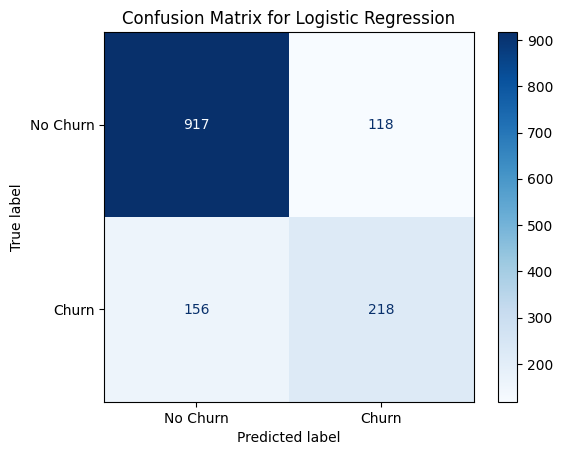

In [34]:
y_pred = best_model.predict(X_test_processed)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
display_cm.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for {best_model_name}')
plt.show()

## 14. ROC-AUC

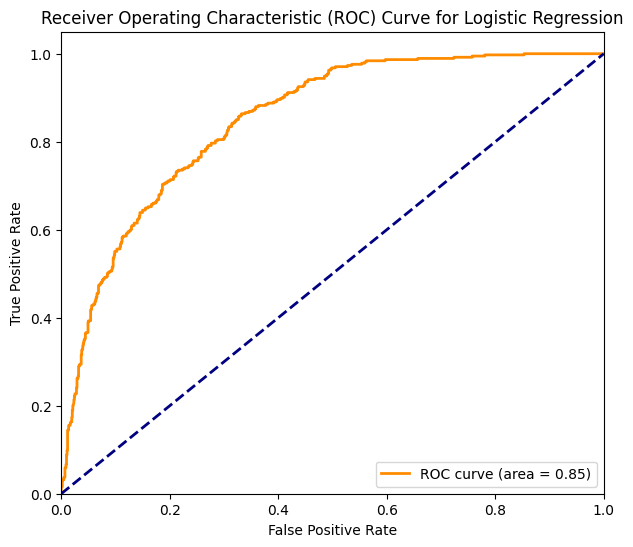

ROC-AUC Score for Logistic Regression: 0.8492


In [35]:
y_proba = best_model.predict_proba(X_test_processed)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'Receiver Operating Characteristic (ROC) Curve for {best_model_name}')
plt.legend(loc="lower right")
plt.show()

print(f"ROC-AUC Score for {best_model_name}: {roc_auc:.4f}")

## 15. Global SHAP Explainability — XAI


SHAP Summary Plot (Global Feature Importance):


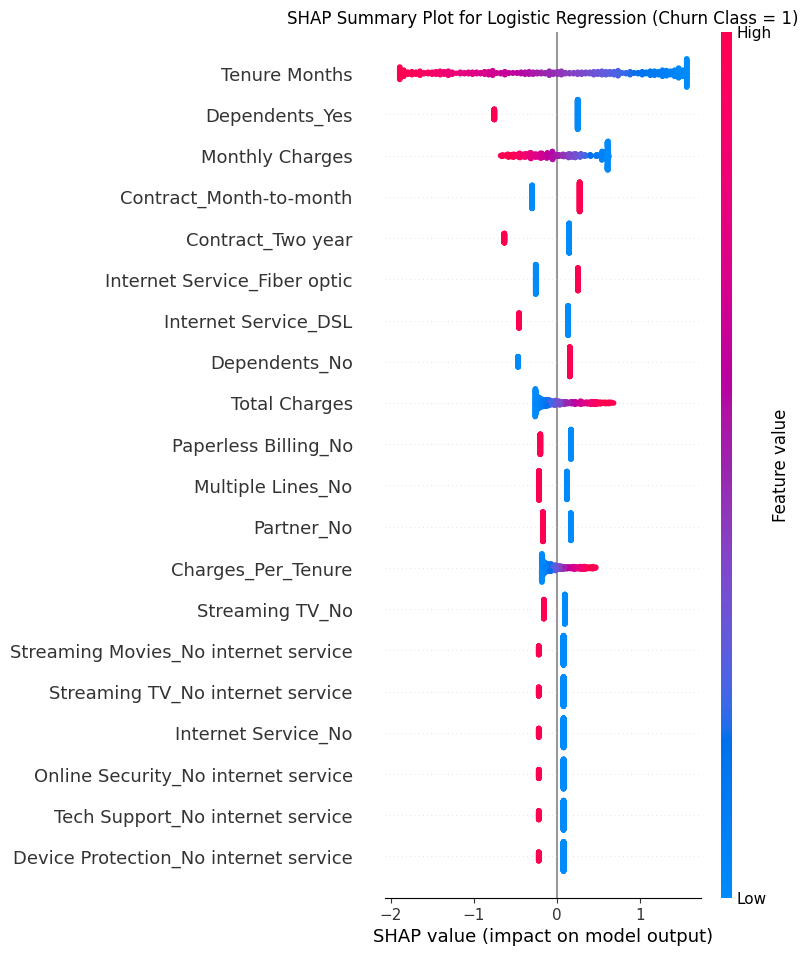


SHAP Bar Plot (Mean Absolute SHAP Value):


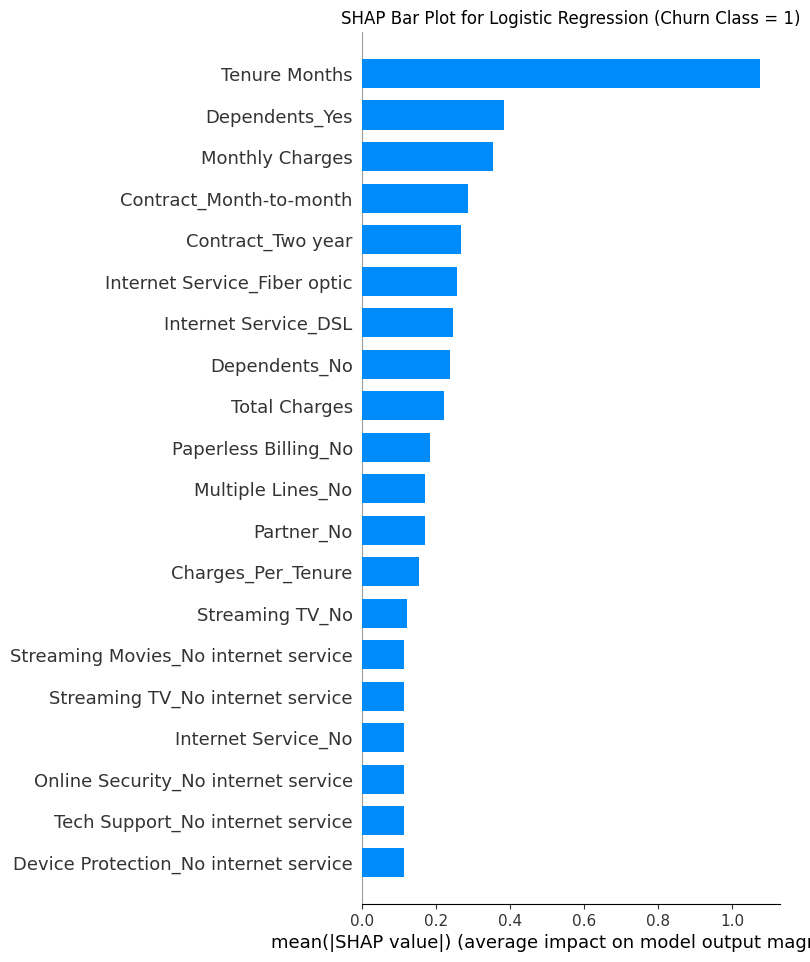


Top 10 Most Important Features (Global SHAP):


,Feature,Mean Absolute SHAP Value
0,Tenure Months,1.074843
12,Dependents_Yes,0.381781
1,Monthly Charges,0.351917
39,Contract_Month-to-month,0.284747
41,Contract_Two year,0.265701
19,Internet Service_Fiber optic,0.254276
18,Internet Service_DSL,0.243363
11,Dependents_No,0.236703
2,Total Charges,0.219080
42,Paperless Billing_No,0.181828


In [36]:
import shap

# XAI 2 - Global SHAP Feature Importance

# Use at most 500 test samples for SHAP value calculation for efficiency
samples_for_shap = X_test_processed.sample(n=min(500, len(X_test_processed)), random_state=42)

# Calculate SHAP values
# Ensure output format is compatible with shap.Explanation
if best_model_name in ['XGBoost', 'LightGBM', 'Random Forest']:
    shap_values_obj = explainer(samples_for_shap)
    # If it's a multi-output explainer, take the churn class (1)
    if len(shap_values_obj.shape) == 3:
        shap_values = shap_values_obj.values[:, :, 1] # Ensure correct slicing for TreeExplainer Explanation object
        expected_value = explainer.expected_value[1] if isinstance(explainer.expected_value, np.ndarray) else explainer.expected_value
    else:
        shap_values = shap_values_obj.values
        expected_value = explainer.expected_value

elif isinstance(best_model, LogisticRegression): # Use model type for clarity here, assuming explainer is linear
    # explainer is already initialized correctly with a background in section 12
    shap_values_raw = explainer.shap_values(samples_for_shap)
    expected_value = explainer.expected_value
    # LinearExplainer returns a list of arrays for binary classification; take class 1
    if isinstance(shap_values_raw, list):
        shap_values = shap_values_raw[1]
    else:
        shap_values = shap_values_raw

    # Create shap.Explanation object for consistency and plotting
    shap_values_obj = shap.Explanation(
        values=shap_values,
        base_values=np.full(shap_values.shape[0], expected_value) if isinstance(expected_value, (float, int, np.number)) else expected_value,
        data=samples_for_shap.values,
        feature_names=feature_names
    )

# 1. SHAP summary plot
print("\nSHAP Summary Plot (Global Feature Importance):")
shap.summary_plot(shap_values_obj, samples_for_shap, plot_type="dot", show=False)
plt.title(f'SHAP Summary Plot for {best_model_name} (Churn Class = 1)')
plt.show()

# 2. SHAP bar plot
print("\nSHAP Bar Plot (Mean Absolute SHAP Value):")
shap.summary_plot(shap_values_obj, samples_for_shap, plot_type="bar", show=False)
plt.title(f'SHAP Bar Plot for {best_model_name} (Churn Class = 1)')
plt.show()

# 3. Top 10 important features table
# Calculate mean absolute SHAP values
mean_abs_shap = np.abs(shap_values_obj.values).mean(axis=0) # Use shap_values_obj.values consistently
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean Absolute SHAP Value': mean_abs_shap
})
feature_importance_df = feature_importance_df.sort_values(by='Mean Absolute SHAP Value', ascending=False)

print("\nTop 10 Most Important Features (Global SHAP):")
display(feature_importance_df.head(10))

## 16. Individual Customer Explanation — XAI

Highest-Risk Customer ID: 5178-LMXOP
Churn Prediction: Yes
Churn Probability: 0.8782
Risk Level: High Risk

SHAP Explanation for the Highest-Risk Customer:


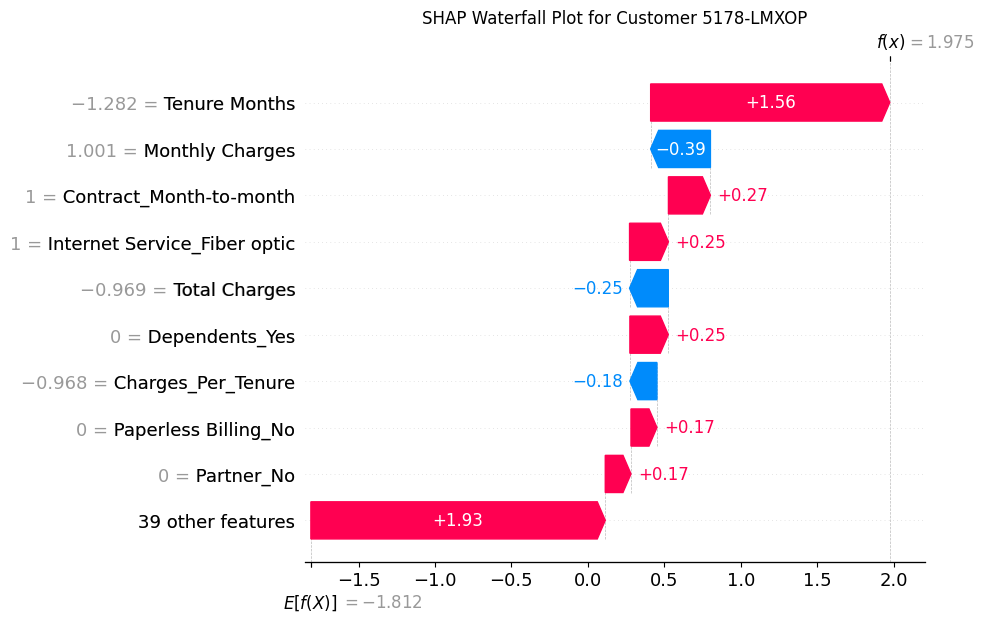


Top 5 Contributing Features for this Customer:


,Feature,Feature Value,SHAP Value
0,Tenure Months,-1.281624,1.564242
1,Monthly Charges,1.001148,-0.390926
39,Contract_Month-to-month,1.000000,0.274675
19,Internet Service_Fiber optic,1.000000,0.254276
2,Total Charges,-0.968657,-0.253384


In [37]:
import matplotlib.pyplot as plt

# XAI 3 - Individual Customer Explanation

# Get predictions and probabilities for the test set
test_predictions = best_model.predict(X_test_processed)
test_probabilities = best_model.predict_proba(X_test_processed)[:, 1]

# Create a DataFrame for test results including original customer_id (aligned by index)
test_results = pd.DataFrame({
    'Customer ID': customer_id.loc[X_test.index],
    'Churn Prediction': test_predictions,
    'Churn Probability': test_probabilities
}).set_index('Customer ID')

# Find the highest-risk customer (highest churn probability)
highest_risk_customer_id = test_results['Churn Probability'].idxmax()
highest_risk_customer_data = test_results.loc[highest_risk_customer_id]

# Get the original numerical index corresponding to the highest_risk_customer_id
# customer_id is a Series where index is original df index and value is CustomerID string
original_idx_for_highest_risk = customer_id[customer_id == highest_risk_customer_id].index[0]
highest_risk_customer_features = X_test_processed.loc[[original_idx_for_highest_risk]] # Use [[idx]] to keep it as DataFrame

# Assign Risk Level
prob = highest_risk_customer_data['Churn Probability']
if prob < 0.30:
    risk_level = 'Low Risk'
elif 0.30 <= prob <= 0.60:
    risk_level = 'Medium Risk'
else:
    risk_level = 'High Risk'

print(f"Highest-Risk Customer ID: {highest_risk_customer_id}")
print(f"Churn Prediction: {'Yes' if highest_risk_customer_data['Churn Prediction'] == 1 else 'No'}")
print(f"Churn Probability: {highest_risk_customer_data['Churn Probability']:.4f}")
print(f"Risk Level: {risk_level}")

# Explain that customer using SHAP
print("\nSHAP Explanation for the Highest-Risk Customer:")

# Recalculate SHAP values for the single highest-risk customer
if best_model_name in ['XGBoost', 'LightGBM', 'Random Forest']:
    single_shap_values_obj = explainer(highest_risk_customer_features)
    if len(single_shap_values_obj.shape) == 3:
        single_shap_values = single_shap_values_obj.values[0, :, 1]  # Get values for class 1
        single_expected_value = explainer.expected_value[1] if isinstance(explainer.expected_value, np.ndarray) else explainer.expected_value
    else:
        single_shap_values = single_shap_values_obj.values[0] # Get values for class 1 if directly accessible
        single_expected_value = explainer.expected_value
elif isinstance(explainer, shap.LinearExplainer):
    single_shap_values_raw = explainer.shap_values(highest_risk_customer_features)
    single_expected_value = explainer.expected_value
    if isinstance(single_shap_values_raw, list):
        single_shap_values = single_shap_values_raw[1]
    else:
        single_shap_values = single_shap_values_raw

# Ensure shap_values is a 1D array
single_shap_values = np.squeeze(single_shap_values)

# Convert to shap.Explanation object for waterfall plot
single_explanation = shap.Explanation(
    values=single_shap_values,
    base_values=single_expected_value,
    data=highest_risk_customer_features.iloc[0].values,
    feature_names=feature_names
)

# 1. SHAP waterfall plot
shap.plots.waterfall(single_explanation, show=False)
plt.title(f'SHAP Waterfall Plot for Customer {highest_risk_customer_id}')
plt.show()

# 2. Top 5 contributing features, SHAP values, and feature values
shap_df = pd.DataFrame({
    'Feature': feature_names,
    'Feature Value': highest_risk_customer_features.iloc[0].values,
    'SHAP Value': single_shap_values
})
shap_df['Absolute SHAP Value'] = np.abs(shap_df['SHAP Value'])
shap_df = shap_df.sort_values(by='Absolute SHAP Value', ascending=False)

print("\nTop 5 Contributing Features for this Customer:")
display(shap_df.head(5).drop(columns='Absolute SHAP Value'))

## 17. Customer Churn Prediction

In [38]:
# Generate predictions for the entire test set
predictions_all = best_model.predict(X_test_processed)
probabilities_all = best_model.predict_proba(X_test_processed)[:, 1]

# Create a clean table for all test customers
churn_predictions_df = pd.DataFrame({
    'Customer ID': customer_id.loc[X_test.index],
    'Churn Probability': probabilities_all,
    'Prediction': predictions_all
})

# Map numerical prediction back to 'Yes'/'No' for clarity
churn_predictions_df['Prediction'] = churn_predictions_df['Prediction'].map({1: 'Yes', 0: 'No'})

# Sort by highest churn probability
churn_predictions_df = churn_predictions_df.sort_values(by='Churn Probability', ascending=False).reset_index(drop=True)

print("Customer Churn Predictions for Test Set (Sorted by Churn Probability):")
display(churn_predictions_df.head(10)) # Display top 10 highest risk customers

Customer Churn Predictions for Test Set (Sorted by Churn Probability):


,Customer ID,Churn Probability,Prediction
0,5178-LMXOP,0.878180,Yes
1,1400-MMYXY,0.857101,Yes
2,6861-XWTWQ,0.856860,Yes
3,8884-ADFVN,0.853075,Yes
4,4587-VVTOX,0.841225,Yes
5,0295-PPHDO,0.840089,Yes
6,4927-WWOOZ,0.834832,Yes
7,6630-UJZMY,0.834330,Yes
8,7180-PISOG,0.833321,Yes
9,7181-BQYBV,0.832393,Yes


## 18. Risk Level — XAI

In [39]:
# XAI 4 - Explainable Risk Analysis

# Assign risk levels based on churn probability
def assign_risk_level(prob):
    if prob < 0.30:
        return 'Low Risk'
    elif 0.30 <= prob <= 0.60:
        return 'Medium Risk'
    else:
        return 'High Risk'

churn_predictions_df['Risk Level'] = churn_predictions_df['Churn Probability'].apply(assign_risk_level)

print("Customer Churn Risk Levels:")
display(churn_predictions_df.groupby('Risk Level')['Customer ID'].count().reset_index(name='Number of Customers'))

print("\nTop 5 High-Risk Customers with their Risk Levels:")
display(churn_predictions_df[churn_predictions_df['Risk Level'] == 'High Risk'].head(5))

Customer Churn Risk Levels:


,Risk Level,Number of Customers
0,High Risk,230
1,Low Risk,886
2,Medium Risk,293



Top 5 High-Risk Customers with their Risk Levels:


,Customer ID,Churn Probability,Prediction,Risk Level
0,5178-LMXOP,0.878180,Yes,High Risk
1,1400-MMYXY,0.857101,Yes,High Risk
2,6861-XWTWQ,0.856860,Yes,High Risk
3,8884-ADFVN,0.853075,Yes,High Risk
4,4587-VVTOX,0.841225,Yes,High Risk


## 19. Explainable Retention Recommendation — XAI

In [40]:
import pandas as pd
import numpy as np
import shap

# XAI 5 - Explainable Retention Recommendation

def generate_retention_recommendation(customer_feature_values, customer_shap_values, feature_names, customer_id, churn_probability, risk_level):
    shap_data = pd.DataFrame({
        'Feature': feature_names,
        'Feature Value': customer_feature_values,
        'SHAP Value': customer_shap_values
    })

    # Filter for positive SHAP values (features contributing to churn) and sort by magnitude
    churn_contributing_features = shap_data[shap_data['SHAP Value'] > 0].sort_values(by='SHAP Value', ascending=False)

    recommendation = "No specific recommendation for retention based on available features."
    top_contributing_feature = "N/A"

    if not churn_contributing_features.empty:
        top_feature = churn_contributing_features.iloc[0]
        top_contributing_feature = top_feature['Feature']
        feature_value = top_feature['Feature Value']

        # Example recommendations based on common churn drivers
        if 'Contract_Month-to-month' in top_contributing_feature:
            recommendation = "Offer long-term contract options (e.g., 1-year or 2-year) with discounts or incentives to reduce monthly commitment concerns."
        elif 'Internet Service_Fiber optic' in top_contributing_feature:
            recommendation = "Address issues with fiber optic service (e.g., reliability, speed) or offer alternative internet plans."
        elif 'Monthly Charges' in top_contributing_feature:
            recommendation = "Review and optimize their monthly plan to reduce high charges. Consider loyalty discounts or bundled offers."
        elif 'Total Charges' in top_contributing_feature:
            recommendation = "Acknowledge high total charges, possibly by offering a one-time credit or loyalty bonus."
        elif 'Tech Support_No internet service' in top_contributing_feature or 'Tech Support_No' in top_contributing_feature:
            recommendation = "Provide improved or free tech support services, highlighting its value and availability."
        elif 'Online Security_No internet service' in top_contributing_feature or 'Online Security_No' in top_contributing_feature:
            recommendation = "Offer security add-ons or packages, emphasizing protection and peace of mind."
        elif 'Partner_No' in top_contributing_feature or 'Dependents_No' in top_contributing_feature:
            recommendation = "Target family-oriented bundles or benefits that appeal to single individuals or those without dependents."
        elif 'Senior Citizen_1' in top_contributing_feature:
            recommendation = "Provide senior-specific plans or discounts, or simplify service options."
        elif 'Payment Method_Electronic check' in top_contributing_feature:
            recommendation = "Suggest alternative, more secure payment methods and highlight benefits, or offer incentives for switching."
        else:
            recommendation = f"Focus on improving the service related to '{top_contributing_feature}' (current value: {feature_value})."

    return {
        'Customer ID': customer_id,
        'Churn Probability': churn_probability,
        'Risk Level': risk_level,
        'Top Contributing Feature': top_contributing_feature,
        'Recommended Retention Action': recommendation
    }

# Identify high-risk customers
high_risk_customers_df = churn_predictions_df[churn_predictions_df['Risk Level'] == 'High Risk']

retention_recommendations = []

# Iterate through high-risk customers to generate personalized recommendations
for index, row in high_risk_customers_df.iterrows():
    cust_id = row['Customer ID']
    cust_prob = row['Churn Probability']
    cust_risk = row['Risk Level']

    # Get the original numerical index corresponding to the cust_id
    original_idx_for_customer = customer_id[customer_id == cust_id].index[0]
    # Get original features for this customer from X_test_processed
    customer_features_for_shap = X_test_processed.loc[[original_idx_for_customer]] # Use [[idx]] to keep it as DataFrame

    # Calculate SHAP values for this individual customer
    if isinstance(explainer, shap.TreeExplainer):
        cust_shap_values_obj = explainer(customer_features_for_shap)
        if len(cust_shap_values_obj.shape) == 3:
            cust_shap_values = cust_shap_values_obj.values[0, :, 1]  # Get values for class 1
        else:
            cust_shap_values = cust_shap_values_obj.values[0] # Get values for class 1 if directly accessible
    elif isinstance(explainer, shap.LinearExplainer):
        cust_shap_values = explainer.shap_values(customer_features_for_shap)
        if isinstance(cust_shap_values, list):
            cust_shap_values = cust_shap_values[1]

    # Ensure cust_shap_values is a 1D array
    cust_shap_values = np.squeeze(cust_shap_values)

    recommendation = generate_retention_recommendation(
        customer_features_for_shap.iloc[0].values,
        cust_shap_values,
        feature_names,
        cust_id,
        cust_prob,
        cust_risk
    )
    retention_recommendations.append(recommendation)

retention_df = pd.DataFrame(retention_recommendations)

print("Explainable Retention Recommendations for High-Risk Customers:")
display(retention_df.head(10)) # Display top 10 recommendations

Explainable Retention Recommendations for High-Risk Customers:


,Customer ID,Churn Probability,Risk Level,Top Contributing Feature,Recommended Retention Action
0,5178-LMXOP,0.878180,High Risk,Tenure Months,Focus on improving the service related to 'Ten...
1,1400-MMYXY,0.857101,High Risk,Tenure Months,Focus on improving the service related to 'Ten...
2,6861-XWTWQ,0.856860,High Risk,Tenure Months,Focus on improving the service related to 'Ten...
3,8884-ADFVN,0.853075,High Risk,Tenure Months,Focus on improving the service related to 'Ten...
4,4587-VVTOX,0.841225,High Risk,Tenure Months,Focus on improving the service related to 'Ten...
5,0295-PPHDO,0.840089,High Risk,Tenure Months,Focus on improving the service related to 'Ten...
6,4927-WWOOZ,0.834832,High Risk,Tenure Months,Focus on improving the service related to 'Ten...
7,6630-UJZMY,0.834330,High Risk,Tenure Months,Focus on improving the service related to 'Ten...
8,7180-PISOG,0.833321,High Risk,Tenure Months,Focus on improving the service related to 'Ten...
9,7181-BQYBV,0.832393,High Risk,Tenure Months,Focus on improving the service related to 'Ten...


## 20. Final Results

In [41]:
final_results_data = []

# Get results for the best model
best_model_row = results_df[results_df['Model'] == best_model_name].iloc[0]

train_accuracy = best_model_row['Train Accuracy']
test_accuracy = best_model_row['Test Accuracy']
precision = best_model_row['Precision']
recall = best_model_row['Recall']
f1_score_val = best_model_row['F1-score']
roc_auc_val = best_model_row['ROC-AUC']

# Calculate Train-Test Gap
train_test_gap = abs(train_accuracy - test_accuracy)

final_results_data.append({
    'Best Model': best_model_name,
    'Train Accuracy': train_accuracy,
    'Test Accuracy': test_accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1_score_val,
    'ROC-AUC': roc_auc_val,
    'Train-Test Gap': train_test_gap
})

final_results_df = pd.DataFrame(final_results_data)
final_results_df = final_results_df.round(4)

print("Final Model Performance Summary:")
display(final_results_df)

Final Model Performance Summary:


,Best Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,ROC-AUC,Train-Test Gap
0,Logistic Regression,0.8149,0.8055,0.6488,0.5829,0.6141,0.8492,0.0094


## 21. Save Model

In [42]:
joblib.dump(best_model, 'best_churn_model.joblib')
joblib.dump(preprocessor, 'preprocessor.joblib')

print("Model (best_churn_model.joblib) and preprocessor (preprocessor.joblib) saved successfully.")

Model (best_churn_model.joblib) and preprocessor (preprocessor.joblib) saved successfully.
